In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [1]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, LinearRegression

In [6]:
X_train = pd.read_csv("../../03.results/outputs/X_train.csv")
y_train = pd.read_csv("../../03.results/outputs/y_train.csv")
y_reg = y_train["target_next_return"]      
y_clf = y_train["target_direction"]
print(X_train.shape, y_train.shape)

(1787, 40) (1787, 4)


Only X_train and y_train are loaded. The test files are intentionally untouched here.

In [10]:
from evalu import cv_scores, plot_curve

In [11]:
ols   = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
ridge = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1000))])
lasso = Pipeline([("scaler", StandardScaler()), ("model", Lasso(alpha=1e-4, max_iter=20000))])
scores = {n: cv_scores(X_train, m, y_reg, "regression") for n, m in {"OLS": ols, "Ridge": ridge, "Lasso": lasso}.items()}
pd.DataFrame(scores).T[["rmse", "rmse_std", "mae", "r2", "r2_std"]].round(5)

,rmse,rmse_std,mae,r2,r2_std
OLS,0.090665,0.081166,0.075293,-2.642713,4.337923
Ridge,0.049566,0.014953,0.036528,-0.00989,0.015652
Lasso,0.080712,0.064384,0.065959,-1.76766,2.835577


All three have R² around zero or slightly negative: linear models find essentially no stable signal in the next-day return

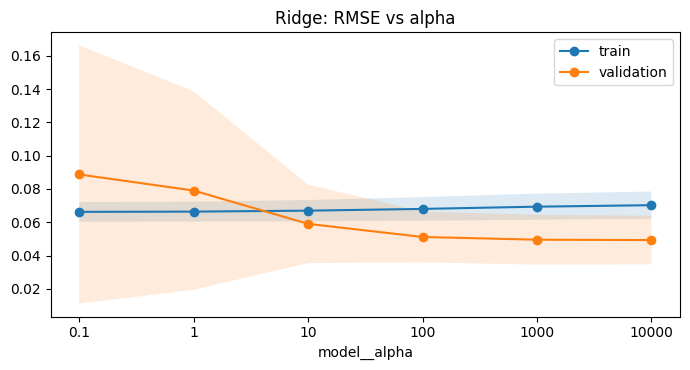

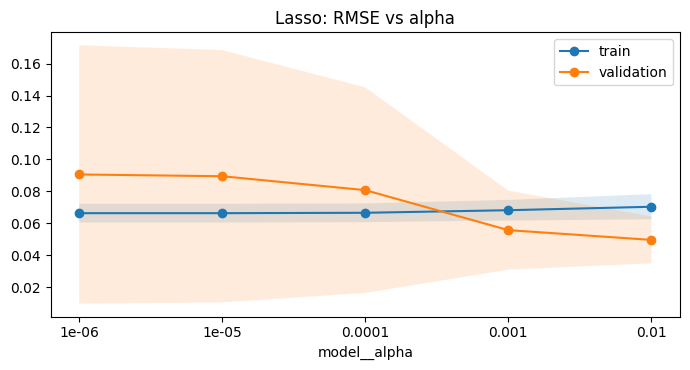

,value,train,validation
0,0.1,0.06629,0.08873
1,1,0.06642,0.07906
2,10,0.06700,0.05909
3,100,0.06805,0.05121
4,1000,0.06939,0.04957
5,10000,0.07029,0.04935


In [12]:
a_r = plot_curve(ridge, X_train, y_reg,  "model__alpha", [0.1, 1, 10, 100, 1000, 10000], "neg_root_mean_squared_error", "Ridge: RMSE vs alpha", "ridge_alpha.png", flip=True)
a_l = plot_curve(lasso, X_train, y_reg, "model__alpha", [1e-6, 1e-5, 1e-4, 1e-3, 1e-2], "neg_root_mean_squared_error", "Lasso: RMSE vs alpha", "lasso_alpha.png", flip=True)
a_r.round(5)

As alpha grows, validation error FALLS toward the error of a constant prediction. Heavy shrinkage wins because there is little signal.

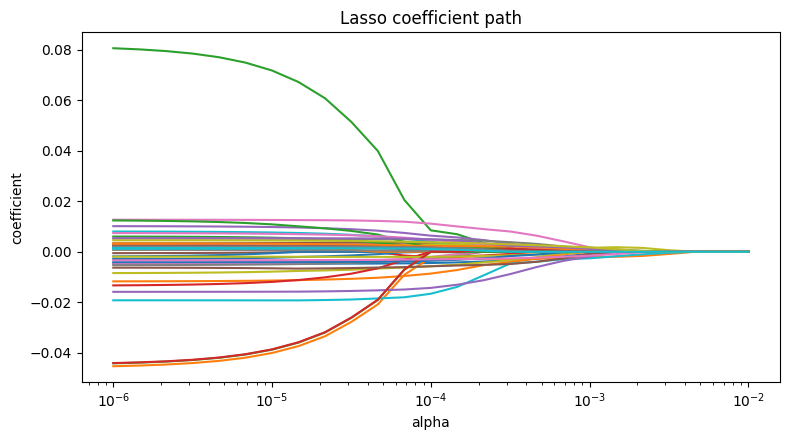

non-zero features at alpha=1e-4: {'Unnamed: 0': -0.0045, 'last_return': -0.0023, 'return_3d': 0.0085, 'returnvola_3d': -0.0022, 'return_7d': 0.0025, 'returnvola_7d': 0.0034, 'return_14d': 0.0111, 'returnvola_14d': -0.0027, 'return_21d': -0.0057, 'returnvola_21d': 0.004, 'returnvola_30d': -0.0087, 'return_60d': 0.0015, 'returnvola_60d': 0.0007, 'return_90d': 0.0064, 'returnvola_90d': 0.0006, 'rsi_14': -0.002, 'bb_width_20': 0.0049, 'high_low_range_pct': 0.0029, 'price_to_sma_7': -0.0166, 'price_to_sma_50': 0.0016, 'price_to_sma_200': -0.0143, 'macd_hist_norm': -0.0058, 'bb_position': 0.0048, 'upper_wick': 0.0003, 'lower_wick': -0.002, 'vol_ratio_7': 0.0018, 'vol_ratio_30': -0.0036, 'log_vol_change': 0.0023, 'ret_lag1': -0.0001, 'ret_lag3': 0.0049, 'dow_sin': 0.0016, 'dow_cos': -0.003, 'month_sin': 0.0017, 'month_cos': 0.0037, 'is_weekend': 0.0011}


In [ ]:
Xs = StandardScaler().fit_transform(X_train)
alphas = np.logspace(-6, -2, 25)
coefs = np.array([Lasso(alpha=a, max_iter=50000).fit(Xs, y_reg).coef_ for a in alphas])
fig, ax = plt.subplots(figsize=(8, 4.5)); ax.plot(alphas, coefs); ax.set_xscale("log"); ax.set_xlabel("alpha"); ax.set_ylabel("coefficient")
ax.set_title("Lasso coefficient path"); plt.tight_layout(); fig.savefig("../../03.results/eda_visualizations/lasso_path.png", dpi=130); plt.show()
m = Lasso(alpha=1e-4, max_iter=50000).fit(Xs, y_reg)
print("non-zero features at alpha=1e-4:", pd.Series(m.coef_, X_train.columns).loc[lambda s: s != 0].round(4).to_dict())

In [14]:
rows = [{"model": "Ridge", **scores["Ridge"]}, {"model": "Lasso", **scores["Lasso"]}]
res = pd.DataFrame(rows); res.to_csv("../../03.results/outputs/model_results_ridge_lasso.csv", index=False); res.round(4)

,model,task,rmse,rmse_std,mae,mae_std,r2,r2_std
0,Ridge,regression,0.0496,0.0150,0.0365,0.0108,-0.0099,0.0157
1,Lasso,regression,0.0807,0.0644,0.0660,0.0575,-1.7677,2.8356
